# Revolut growth and fraud review scaling model

Part 1 splits Revolut's 2025 revenue growth into customer growth and growth per customer.
Part 2 asks what reaching 100m customers could mean for fraud review workload.
Part 3 tests how much a ranked review queue could save, across a range of precision levels.

Reported figures are from Revolut (2026), with growth rates on a GBP basis.
Anything labelled ASSUMPTION is mine. Derived numbers are my calculations, not reported figures.
Rule and model results come from Project 1 (PaySim, simulated data; Lopez-Rojas, Elmir and Axelsson, 2016).

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")   # always work from the project root
os.makedirs("outputs", exist_ok=True)

## Part 1: where did growth come from?

In [2]:
CUSTOMER_GROWTH = 0.30   # retail customers, reported
GROUP_REVENUE_GROWTH = 0.46  # group revenue, reported

lines = pd.DataFrame({
    "line": ["Subscriptions", "Card payments", "FX", "Wealth", "Interest income"],
    "revenue_2025_usd_m": [936, 1300, 800, 876, 1300],   # reported; lines overlap and do not sum to group revenue
    "revenue_growth": [0.67, 0.45, 0.43, 0.31, 0.23],    # reported
})
lines["growth_per_customer"] = (1 + lines["revenue_growth"]) / (1 + CUSTOMER_GROWTH) - 1
lines = lines.sort_values("growth_per_customer", ascending=False).reset_index(drop=True)

group_per_customer = (1 + GROUP_REVENUE_GROWTH) / (1 + CUSTOMER_GROWTH) - 1
print(f"Group revenue per retail customer grew about {group_per_customer:.1%} "
      f"(revenue +{GROUP_REVENUE_GROWTH:.0%}, customers +{CUSTOMER_GROWTH:.0%}).")
lines.round(3)

Group revenue per retail customer grew about 12.3% (revenue +46%, customers +30%).


,line,revenue_2025_usd_m,revenue_growth,growth_per_customer
0,Subscriptions,936,0.67,0.285
1,Card payments,1300,0.45,0.115
2,FX,800,0.43,0.100
3,Wealth,876,0.31,0.008
4,Interest income,1300,0.23,-0.054


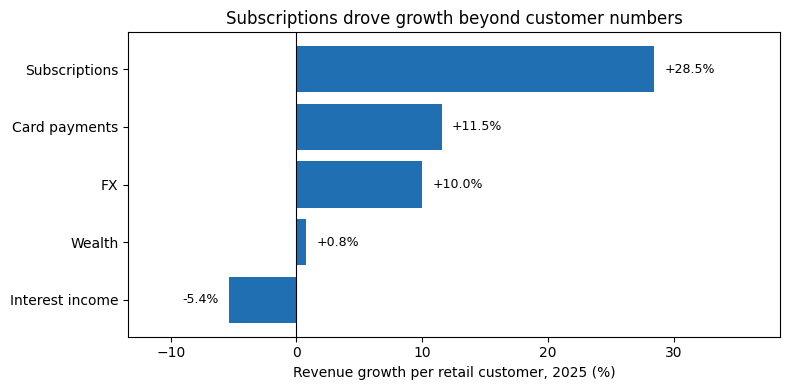

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
vals = lines["growth_per_customer"] * 100
bars = ax.barh(lines["line"], vals, color="#1f6fb2")
ax.axvline(0, color="black", lw=0.8)
ax.invert_yaxis()
for b, v in zip(bars, vals):
    ax.text(v + (0.8 if v >= 0 else -0.8), b.get_y() + b.get_height() / 2, f"{v:+.1f}%",
            va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.set_xlabel("Revenue growth per retail customer, 2025 (%)")
ax.set_title("Subscriptions drove growth beyond customer numbers")
ax.set_xlim(min(vals.min() - 8, -10), vals.max() + 10)
fig.tight_layout()
fig.savefig("outputs/revolut_growth_per_customer.png", dpi=160)
lines.to_csv("outputs/revolut_growth_by_line.csv", index=False)

## Part 2: the 100m customer target

In [4]:
CUSTOMERS_2025_M = 68.3   # reported retail customers
TARGET_M = 100            # Revolut's stated target for mid-2027
YEARS = 1.5               # end 2025 to mid 2027

needed = TARGET_M / CUSTOMERS_2025_M - 1
annual = (TARGET_M / CUSTOMERS_2025_M) ** (1 / YEARS) - 1
print(f"Reaching {TARGET_M}m needs {needed:.0%} more customers, about {annual:.0%} a year "
      f"(2025 growth was {CUSTOMER_GROWTH:.0%}).")

Reaching 100m needs 46% more customers, about 29% a year (2025 growth was 30%).


## Part 3: reviewer need, fixed rule versus ranked queue

Reviewers needed scale with alerts per fraud case caught, which is 1 divided by precision.
Project 1 gave a fixed rule precision of 0.83% and a model-ranked queue precision of 74.1% on simulated data.
Real precision will be lower, so the ranked queue is tested across a range.

In [5]:
P_RULE = 0.0083               # Project 1, fixed drained-account rule
P_RANKED_SIMULATED = 0.7411   # Project 1, ranked queue at 360 alerts a day (simulated data)
REVIEWS_PER_ANALYST = 36      # ASSUMPTION: 10 minutes per review, 6 productive hours a day

precisions = [P_RULE, 0.02, 0.05, 0.10, 0.25, 0.50, P_RANKED_SIMULATED]
sens = pd.DataFrame({"precision": precisions})
sens["reviewers_per_100_cases_a_day"] = 100 / sens["precision"] / REVIEWS_PER_ANALYST
sens["saving_vs_fixed_rule"] = 1 - P_RULE / sens["precision"]
sens["label"] = ["Fixed rule"] + [""] * 5 + ["Ranked (simulated)"]
sens.round(3)

,precision,reviewers_per_100_cases_a_day,saving_vs_fixed_rule,label
0,0.008,334.672,0.000,Fixed rule
1,0.020,138.889,0.585,
2,0.050,55.556,0.834,
3,0.100,27.778,0.917,
4,0.250,11.111,0.967,
5,0.500,5.556,0.983,
6,0.741,3.748,0.989,Ranked (simulated)


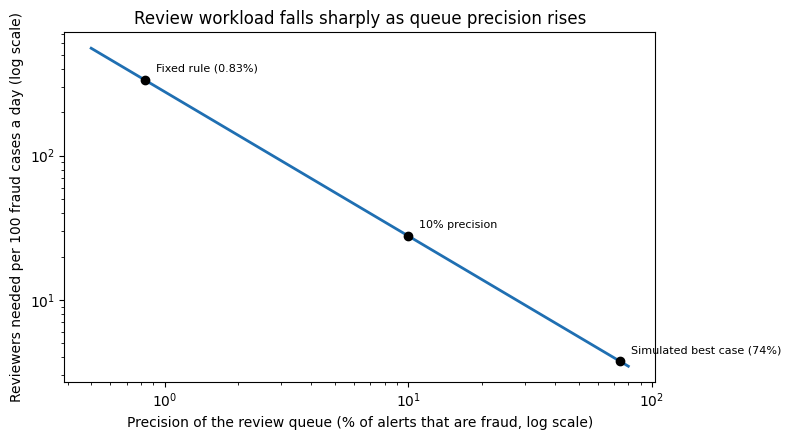

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
xs = np.geomspace(0.005, 0.8, 100)
ax.plot(xs * 100, 100 / xs / REVIEWS_PER_ANALYST, color="#1f6fb2", lw=2)
for p, lab in [(P_RULE, "Fixed rule (0.83%)"), (0.10, "10% precision"), (P_RANKED_SIMULATED, "Simulated best case (74%)")]:
    y = 100 / p / REVIEWS_PER_ANALYST
    ax.scatter([p * 100], [y], color="black", zorder=5)
    ax.annotate(lab, (p * 100, y), xytext=(8, 6), textcoords="offset points", fontsize=8)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Precision of the review queue (% of alerts that are fraud, log scale)")
ax.set_ylabel("Reviewers needed per 100 fraud cases a day (log scale)")
ax.set_title("Review workload falls sharply as queue precision rises")
fig.tight_layout()
fig.savefig("outputs/revolut_reviewer_sensitivity.png", dpi=160)
sens.to_csv("outputs/reviewer_sensitivity.csv", index=False)

### Combined scenarios at 100m customers
Index of reviewers needed, where end-2025 with the fixed rule = 100.
ASSUMPTION: fraud cases per customer rise by the multiplier shown. The 10x review growth Revolut reports has no stated baseline.

In [7]:
case_index = TARGET_M / CUSTOMERS_2025_M
rows = []
for name, p in [("Fixed rule", P_RULE), ("Ranked, 10% precision", 0.10),
                ("Ranked, 25% precision", 0.25), ("Ranked, 74% (simulated)", P_RANKED_SIMULATED)]:
    row = {"approach": name}
    for m in [1.0, 1.5, 2.0]:
        row[f"fraud per customer x{m}"] = round(100 * case_index * m * P_RULE / p, 1)
    rows.append(row)
scenarios = pd.DataFrame(rows)
scenarios.to_csv("outputs/customer_scenarios.csv", index=False)
scenarios

,approach,fraud per customer x1.0,fraud per customer x1.5,fraud per customer x2.0
0,Fixed rule,146.4,219.6,292.8
1,"Ranked, 10% precision",12.2,18.2,24.3
2,"Ranked, 25% precision",4.9,7.3,9.7
3,"Ranked, 74% (simulated)",1.6,2.5,3.3
